# Part 1: the county layer

**Goal:** one feature per county (50 states + DC) with

| Property | Meaning |
|---|---|
| `geoid` | 5-digit county FIPS from the boundary file |
| `name` | Census name with suffix (`NAMELSAD`) |
| `state` | USPS code (`STUSPS`) |
| `hpi_yoy_pct` | % change in `HPI` from year L-1 to the latest year L |
| `hpi_cagr_5y_pct` | compound annual growth of `HPI` from L-5 to L, in % |
| `status` | `published` when the value is FHFA's own county figure, plus statuses we define |

**Outputs:** `output/counties.parquet` (full resolution) and `output/counties.geojson` (RFC 7946, ≤ 8 MB, no gaps or overlaps).

This notebook is the prototype for `src/part1.py`. Each step prints checks so the decisions can be reviewed before the code moves into the module.

In [1]:
import io
import json
import re
import subprocess
import sys
from datetime import datetime
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import openpyxl
import pandas as pd
import shapely

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = ROOT / "data"
OUTPUT_DIR = ROOT / "output"
BOUNDARIES = DATA_DIR / "census" / "cb_2024_us_county_500k.zip"
TERRITORIES = {"60", "66", "69", "72", "78"}

RELEASE_DIR = DATA_DIR / "fhfa" / "next_release"   # the release that contains 2025; DATA_DIR / "fhfa" is the older one (ends 2024)
LATEST_YEAR = 2025                                  # set to None to detect it from the release

## Step 1: Read the FHFA county release

- The header is on sheet row 6. Read `FIPS code` as text so leading zeros survive.
- Missing values are blank cells, which pandas reads as `NaN`.
- The release date ("Last updated: ...") is in the preamble. Part 3 needs it, and it's handy for labelling now.

In [2]:
def read_release_date(path: Path) -> datetime:
    ws = openpyxl.load_workbook(path, read_only=True).worksheets[0]
    for (cell,) in ws.iter_rows(max_row=6, max_col=1, values_only=True):
        m = re.search(r"Last updated:\s*(.+?)\.?\s*$", str(cell or ""))
        if m:
            return datetime.strptime(m.group(1), "%B %d, %Y")
    raise ValueError(f"no 'Last updated' line in {path}")


def read_fhfa_county(path: Path) -> pd.DataFrame:
    df = pd.read_excel(path, skiprows=5, dtype={"FIPS code": str})
    df = df.rename(columns={"State": "state", "County": "county", "FIPS code": "fips", "Year": "year", "HPI": "hpi"})
    return df[["fips", "state", "county", "year", "hpi"]]


county_xlsx = RELEASE_DIR / "hpi_at_county.xlsx"
release_date = read_release_date(county_xlsx)
hpi = read_fhfa_county(county_xlsx)
print("release:", RELEASE_DIR.relative_to(ROOT), "| published", release_date.date())
print(hpi.shape, "| counties:", hpi.fips.nunique(), "| years:", hpi.year.min(), "-", hpi.year.max())
assert not hpi.duplicated(["fips", "year"]).any()
assert hpi.fips.str.fullmatch(r"\d{5}").all()
hpi.head()

release: data\fhfa\next_release | published 2026-03-31
(106252, 5) | counties: 2795 | years: 1975 - 2025


,fips,state,county,year,hpi
0,01001,AL,Autauga,1986,100.00
1,01001,AL,Autauga,1987,97.86
2,01001,AL,Autauga,1988,101.77
3,01001,AL,Autauga,1989,105.37
4,01001,AL,Autauga,1990,104.77


## Step 2: Define the latest year

First, how many counties have a value in each recent year? If the newest year were only partly filled in (a preliminary year), using it would blank out many counties.

In [3]:
counts = hpi.dropna(subset=["hpi"]).groupby("year").fips.nunique().rename("counties_with_hpi")
w = hpi.pivot(index="fips", columns="year", values="hpi").notna()
years = list(range(int(hpi.year.max()) - 5, int(hpi.year.max()) + 1))
pd.DataFrame({
    "rows in file": hpi.groupby("year").size().reindex(years),
    "counties with hpi": counts.reindex(years),
    "lost vs year before": [(w[y - 1] & ~w[y]).sum() for y in years],
    "gained vs year before": [(~w[y - 1] & w[y]).sum() for y in years],
}, index=pd.Index(years, name="year"))

,rows in file,counties with hpi,lost vs year before,gained vs year before
year,,,,
2020,2791,2791,0,21
2021,2795,2794,1,4
2022,2795,2756,38,0
2023,2795,2665,106,15
2024,2795,2666,66,67
2025,2795,2677,54,65


For both releases the newest year is complete: old release 2024 = 2,633 counties (2023: 2,621); next release 2025 = 2,677 (2024: 2,666). The old release has no 2025 rows at all.

**Decision:** L = **2025**, set explicitly in `LATEST_YEAR`. The table above shows 2025 is complete in the next release: every county in the file has a 2025 row, 2,677 counties have a value (more than 2024's 2,666), and the counties lost and gained versus the year before are in line with earlier years. The older release has no 2025 at all, so building it with `LATEST_YEAR = 2025` stops with an error instead of producing an empty layer.

With `LATEST_YEAR = None`, L is detected as the newest year whose coverage is at least 90% of the year before.

L is one year for the whole layer, never each county's own last year with data. Otherwise a county whose series ended in 2021 would show "2021 vs 2020" on a map labelled with the latest year, which is wrong and invisible to the analyst. If a county has no value for L, its metrics are null.

In [4]:
MIN_COVERAGE = 0.9

def latest_year(hpi: pd.DataFrame, min_coverage: float = MIN_COVERAGE) -> int:
    counts = hpi.dropna(subset=["hpi"]).groupby("year").fips.nunique()
    for year in sorted(counts.index, reverse=True):
        prev = counts.get(year - 1)
        if prev is None or counts[year] >= min_coverage * prev:
            return int(year)
        print(f"skipping {year}: {counts[year]} counties vs {prev} in {year - 1}")
    raise ValueError("no usable latest year")


if LATEST_YEAR is None:
    L = latest_year(hpi)
else:
    L = LATEST_YEAR
    n = counts.get(L, 0)
    assert n >= MIN_COVERAGE * counts.get(L - 1, 0) > 0, (
        f"{RELEASE_DIR.relative_to(ROOT)} has {n} counties with an HPI for {L}; "
        f"pick the release that contains {L} or set LATEST_YEAR = None")
print("latest year L =", L, "| L-1 =", L - 1, "| L-5 =", L - 5)
last_obs = hpi.dropna(subset=["hpi"]).groupby("fips").year.max()
print("counties whose own last value is before L:", (last_obs < L).sum())

latest year L = 2025 | L-1 = 2024 | L-5 = 2020
counties whose own last value is before L: 118


## Step 3: Compute the two metrics from exact years

- `hpi_yoy_pct = (HPI[L] / HPI[L-1] - 1) × 100`
- `hpi_cagr_5y_pct = ((HPI[L] / HPI[L-5]) ^ (1/5) - 1) × 100`

We use the `HPI` column (base 100 in the county's first year). Any base gives the same ratios, because ratios don't depend on the base.

**Decision:** if a required year is missing, the metric is null. We never fall back to the nearest available year. For example, a series with a gap at L-1 gets no YoY, but can still have a 5-year CAGR.

In [5]:
def compute_metrics(hpi: pd.DataFrame, latest: int) -> pd.DataFrame:
    wide = hpi.pivot(index="fips", columns="year", values="hpi").reindex(columns=[latest - 5, latest - 1, latest])
    out = pd.DataFrame(index=wide.index)
    out["hpi_yoy_pct"] = (wide[latest] / wide[latest - 1] - 1) * 100
    out["hpi_cagr_5y_pct"] = ((wide[latest] / wide[latest - 5]) ** (1 / 5) - 1) * 100
    out["hpi_latest"] = wide[latest]
    out["has_L"] = wide[latest].notna()
    out["has_L1"] = wide[latest - 1].notna()
    out["has_L5"] = wide[latest - 5].notna()
    return out


metrics = compute_metrics(hpi, L)
metrics[["hpi_yoy_pct", "hpi_cagr_5y_pct", "hpi_latest"]].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
hpi_yoy_pct,2612.0,4.06,5.66,-23.97,1.39,3.82,6.19,53.04
hpi_cagr_5y_pct,2674.0,8.78,2.05,0.59,7.59,8.89,10.10,18.90
hpi_latest,2677.0,515.58,345.12,111.93,300.37,404.19,611.93,2957.37


In [6]:
# Spot check by hand: the first county in the file
f = metrics.index[0]
s = hpi[hpi.fips == f].set_index("year").hpi
print(f, "HPI", {y: s.get(y) for y in (L - 5, L - 1, L)})
print("yoy  by hand:", round((s[L] / s[L - 1] - 1) * 100, 4), "| computed:", round(metrics.loc[f, "hpi_yoy_pct"], 4))
print("cagr by hand:", round(((s[L] / s[L - 5]) ** 0.2 - 1) * 100, 4), "| computed:", round(metrics.loc[f, "hpi_cagr_5y_pct"], 4))

01001 HPI {2020: np.float64(193.66), 2024: np.float64(280.45), 2025: np.float64(285.46)}
yoy  by hand: 1.7864 | computed: 1.7864
cagr by hand: 8.069 | computed: 8.069


In [7]:
# Counties where only one of the two metrics can be computed
one_only = metrics[metrics.hpi_yoy_pct.isna() != metrics.hpi_cagr_5y_pct.isna()]
print("counties with exactly one metric:", len(one_only))
one_only[["hpi_yoy_pct", "hpi_cagr_5y_pct", "has_L", "has_L1", "has_L5"]].head()

counties with exactly one metric: 64


,hpi_yoy_pct,hpi_cagr_5y_pct,has_L,has_L1,has_L5
fips,,,,,
01023,NaN,4.904695,True,False,True
01075,NaN,7.920852,True,False,True
01085,NaN,4.818868,True,False,True
01131,NaN,3.844566,True,False,True
05097,NaN,11.607814,True,False,True


## Step 4: Status

Each metric needs specific years: YoY needs HPI[L] and HPI[L-1], and CAGR needs HPI[L] and HPI[L-5]. The status says **which** of those is missing, so an analyst can tell why a value is blank. FHFA leaves a year blank when the county's sample is too small.

| Status | HPI[L] | HPI[L-1] | HPI[L-5] | `hpi_yoy_pct` | `hpi_cagr_5y_pct` |
|---|---|---|---|---|---|
| `published` | ✓ | ✓ | ✓ | ✓ | ✓ |
| `partial_no_yoy` | ✓ | ✗ | ✓ | null | ✓ |
| `partial_no_cagr` | ✓ | ✓ | ✗ | ✓ | null |
| `no_prior_years` | ✓ | ✗ | ✗ | null | null |
| `no_latest` | ✗ | any | any | null | null |
| `not_in_fhfa` | county not in the FHFA file at all | | | null | null |

Every non-null value, whatever the status, is computed only from FHFA's own county index. `published` is reserved for counties where **both** values are there.

In [8]:
def assign_status(m: pd.DataFrame) -> pd.Series:
    """m: one row per FHFA county with has_L / has_L1 / has_L5"""
    status = pd.Series("no_latest", index=m.index)
    status[m.has_L & ~m.has_L1 & ~m.has_L5] = "no_prior_years"
    status[m.has_L & ~m.has_L1 & m.has_L5] = "partial_no_yoy"
    status[m.has_L & m.has_L1 & ~m.has_L5] = "partial_no_cagr"
    status[m.has_L & m.has_L1 & m.has_L5] = "published"
    return status


metrics["status"] = assign_status(metrics)
metrics.groupby(["status", "has_L", "has_L1", "has_L5"]).size().rename("counties").to_frame()

counties
status          has_L has_L1 has_L5          
no_latest       False False  False          1
                             True          63
                      True   True          54
no_prior_years  True  False  False          2
partial_no_cagr True  True   False          1
partial_no_yoy  True  False  True          63
published       True  True   True        2611

## Step 5: Boundaries, the frame of the layer

The boundary file decides **which** counties exist: every county in the 50 states + DC gets exactly one feature, with or without data. FHFA rows that don't match a boundary county can't be drawn, so we list them.

In [9]:
bnd = gpd.read_file(BOUNDARIES, columns=["GEOID", "STATEFP", "NAMELSAD", "STUSPS"])
bnd = bnd[~bnd.STATEFP.isin(TERRITORIES)].to_crs(4326)
bnd = bnd.rename(columns={"GEOID": "geoid", "NAMELSAD": "name", "STUSPS": "state"})[["geoid", "name", "state", "geometry"]]
bnd = bnd.sort_values("geoid").reset_index(drop=True)
print("boundary counties:", len(bnd), "| states + DC:", bnd.state.nunique(), "| CRS:", bnd.crs)

unmatched = sorted(set(metrics.index) - set(bnd.geoid))
print("FHFA counties with no boundary feature (dropped):", unmatched)

boundary counties: 3144 | states + DC: 51 | CRS: EPSG:4326
FHFA counties with no boundary feature (dropped): []


In [10]:
# Do FHFA's state codes agree with the boundary file for matched counties?
fh_state = hpi.drop_duplicates("fips").set_index("fips").state
chk = bnd.set_index("geoid").join(fh_state.rename("fhfa_state"), how="inner")
print("state mismatches:", (chk.state != chk.fhfa_state).sum())

state mismatches: 0


## Step 6: Assemble the layer

In [11]:
layer = bnd.join(metrics[["hpi_yoy_pct", "hpi_cagr_5y_pct", "status"]], on="geoid")
layer["status"] = layer.status.fillna("not_in_fhfa")
layer = layer[["geoid", "name", "state", "hpi_yoy_pct", "hpi_cagr_5y_pct", "status", "geometry"]]

# every status must line up with which values are present
expected_present = {"published": (True, True), "partial_no_yoy": (False, True), "partial_no_cagr": (True, False),
                    "no_prior_years": (False, False), "no_latest": (False, False), "not_in_fhfa": (False, False)}
assert layer.geoid.is_unique and len(layer) == len(bnd)
for s, (yoy, cagr) in expected_present.items():
    rows = layer[layer.status == s]
    assert (rows.hpi_yoy_pct.notna() == yoy).all() and (rows.hpi_cagr_5y_pct.notna() == cagr).all(), s

layer.status.value_counts().rename("counties").to_frame()

,counties
status,
published,2611
not_in_fhfa,349
no_latest,118
partial_no_yoy,63
no_prior_years,2
partial_no_cagr,1


In [12]:
layer.drop(columns="geometry").head()

,geoid,name,state,hpi_yoy_pct,hpi_cagr_5y_pct,status
0,01001,Autauga County,AL,1.786415,8.068984,published
1,01003,Baldwin County,AL,2.255816,9.302738,published
2,01005,Barbour County,AL,0.646386,4.634287,published
3,01007,Bibb County,AL,-1.179954,6.980182,published
4,01009,Blount County,AL,-0.682399,7.617207,published


In [13]:
layer[layer.state == "CT"].drop(columns="geometry")

,geoid,name,state,hpi_yoy_pct,hpi_cagr_5y_pct,status
309,09110,Capitol Planning Region,CT,5.743659,10.074065,published
310,09120,Greater Bridgeport Planning Region,CT,5.749619,10.390129,published
311,09130,Lower Connecticut River Valley Planning Region,CT,5.593110,9.902108,published
312,09140,Naugatuck Valley Planning Region,CT,6.407765,10.517165,published
313,09150,Northeastern Connecticut Planning Region,CT,6.634615,10.105485,published
314,09160,Northwest Hills Planning Region,CT,6.818079,10.509616,published
315,09170,South Central Connecticut Planning Region,CT,6.305022,9.984195,published
316,09180,Southeastern Connecticut Planning Region,CT,7.456927,10.577401,published
317,09190,Western Connecticut Planning Region,CT,5.827336,9.330163,published


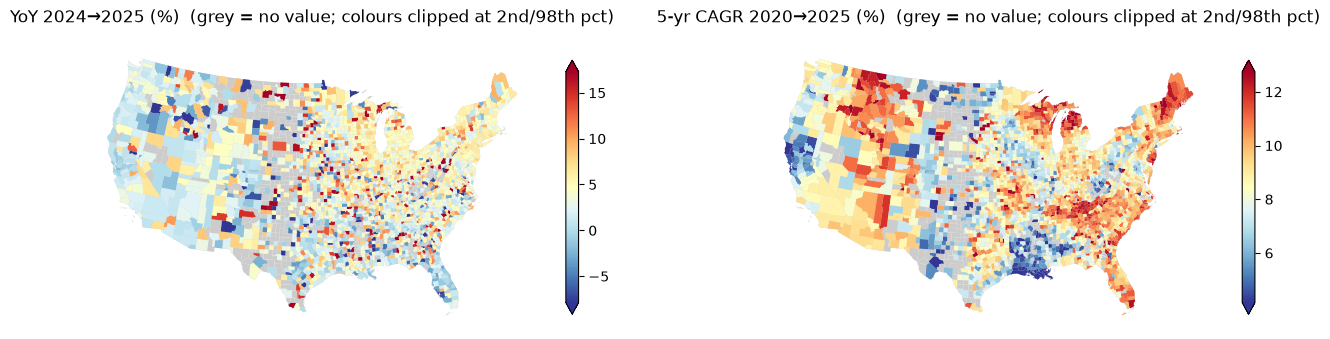

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
lower48 = layer[~layer.state.isin(["AK", "HI"])].to_crs(5070)
for ax, col, title in [(axes[0], "hpi_yoy_pct", f"YoY {L - 1}→{L} (%)"), (axes[1], "hpi_cagr_5y_pct", f"5-yr CAGR {L - 5}→{L} (%)")]:
    lower48.plot(ax=ax, color="#ccc", linewidth=0)
    vals = lower48[col].dropna()
    lower48.dropna(subset=[col]).plot(ax=ax, column=col, cmap="RdYlBu_r", vmin=vals.quantile(.02), vmax=vals.quantile(.98),
                                       legend=True, linewidth=0, legend_kwds={"shrink": .6})
    ax.set_title(title + "  (grey = no value; colours clipped at 2nd/98th pct)"); ax.set_axis_off()

## Step 7: Write the full-resolution GeoParquet

This keeps the original geometry, reprojected from NAD83 (EPSG:4269) to WGS84 (EPSG:4326) so that both outputs share one CRS. For US data the shift between them is sub-metre.

In [15]:
OUTPUT_DIR.mkdir(exist_ok=True)
layer.to_parquet(OUTPUT_DIR / "counties.parquet", index=False)
print(f"counties.parquet: {(OUTPUT_DIR / 'counties.parquet').stat().st_size / 1e6:.1f} MB")

counties.parquet: 16.4 MB


## Step 8: A web-ready GeoJSON (≤ 8 MB, no gaps or overlaps)

The full geometry is ~29 MB as GeoJSON. Simplifying each county **on its own** (e.g. `GeoSeries.simplify`) would move the two copies of a shared border differently and open slivers between neighbours.

**Decision:** use `shapely.coverage_simplify`, which treats the counties as one coverage, so each shared edge is simplified once and both neighbours keep it. Then:
- round to 5 decimals (~1 m), explicitly, so that what we validate is exactly what gets written;
- compare against the Census file itself, which already has a few narrow "gaps": real water channels between coastal counties, because the cartographic file is clipped to the shoreline. The test is "no **new** gaps", not "zero";
- write RFC 7946 GeoJSON: WGS84 lon/lat, no `crs` member.

In [16]:
assert shapely.coverage_is_valid(layer.geometry.values), "input boundaries are not a clean coverage"

def simplify_coverage(gdf: gpd.GeoDataFrame, tolerance: float, grid: float = 1e-5) -> gpd.GeoDataFrame:
    geoms = shapely.coverage_simplify(gdf.geometry.values, tolerance=tolerance, simplify_boundary=True)
    geoms = shapely.set_precision(geoms, grid_size=grid)
    return gdf.set_geometry(gpd.GeoSeries(geoms, index=gdf.index, crs=gdf.crs))


def geojson_bytes(gdf: gpd.GeoDataFrame) -> bytes:
    buf = io.BytesIO()
    gdf.to_file(buf, driver="GeoJSON", RFC7946="YES", COORDINATE_PRECISION=5)
    return buf.getvalue()


def narrow_gaps(gdf: gpd.GeoDataFrame) -> set[str]:
    """geoids whose edges sit next to a gap narrower than ~100 m"""
    edges = shapely.coverage_invalid_edges(gdf.geometry.values, gap_width=1e-3)
    return set(gdf.geoid[~shapely.is_empty(edges)])


ORIGINAL_GAPS = narrow_gaps(layer)
print(f"narrow gaps already in the Census file: {len(ORIGINAL_GAPS)} counties, e.g.",
      sorted(layer[layer.geoid.isin(ORIGINAL_GAPS)].name)[:6])


def check_web_layer(gdf: gpd.GeoDataFrame) -> dict:
    g = gdf.geometry.values
    return {
        "all valid": bool(shapely.is_valid(g).all()),
        "none empty": not bool(shapely.is_empty(g).any()),
        "coverage valid (no overlaps / mismatched edges)": bool(shapely.coverage_is_valid(g)),
        "new gaps vs Census file": sorted(narrow_gaps(gdf) - ORIGINAL_GAPS),
    }


for tol in (0.002, 0.005, 0.01):
    t = simplify_coverage(layer, tol)
    print(f"tolerance {tol}: {len(geojson_bytes(t)) / 1e6:.2f} MB |", check_web_layer(t))

narrow gaps already in the Census file: 23 counties, e.g. ['Anchorage Municipality', 'Calhoun County', 'Cape May County', 'Coos County', 'Dillingham Census Area', 'Galveston County']


tolerance 0.002: 12.86 MB | {'all valid': True, 'none empty': True, 'coverage valid (no overlaps / mismatched edges)': False, 'new gaps vs Census file': ['13037', '13095', '22007', '22045', '22099', '53025', '53077']}


tolerance 0.005: 6.53 MB | {'all valid': True, 'none empty': True, 'coverage valid (no overlaps / mismatched edges)': True, 'new gaps vs Census file': []}


tolerance 0.01: 4.02 MB | {'all valid': True, 'none empty': True, 'coverage valid (no overlaps / mismatched edges)': True, 'new gaps vs Census file': ['48007']}


**Decision:** tolerance **0.005°**. It's the most detail that stays valid after rounding and fits under 8 MB with headroom. At 0.002° the file is too big and rounding breaks the coverage.

How much does it distort small counties? Compare areas in an equal-area projection:

In [17]:
TOLERANCE = 0.005
web = simplify_coverage(layer, TOLERANCE)
a0 = layer.to_crs(5070).area
a1 = web.to_crs(5070).area
ratio = (a1 / a0)
print(ratio.describe(percentiles=[.001, .01, .5, .99]).round(4))
layer.assign(area_ratio=ratio.values).sort_values("area_ratio").drop(columns="geometry").head(5)

count    3144.0000
mean        1.0000
std         0.0018
min         0.9669
0.1%        0.9781
1%          0.9969
50%         1.0000
99%         1.0022
max         1.0397
dtype: float64


,geoid,name,state,hpi_yoy_pct,hpi_cagr_5y_pct,status,area_ratio
2928,51620,Franklin city,VA,-1.703951,6.611594,published,0.966858
2918,51520,Bristol city,VA,0.956208,10.548380,published,0.971510
2933,51670,Hopewell city,VA,2.227631,10.536861,published,0.973823
2925,51595,Emporia city,VA,NaN,9.581135,partial_no_yoy,0.977352
2954,51840,Winchester city,VA,6.202952,9.387110,published,0.982584


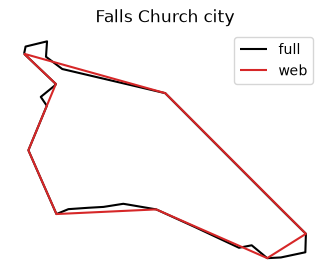

In [18]:
# Smallest county, before and after
small = layer.assign(a=a0.values).sort_values("a").geoid.iloc[0]
fig, ax = plt.subplots(figsize=(4, 4))
layer[layer.geoid == small].boundary.plot(ax=ax, color="black", label="full")
web[web.geoid == small].boundary.plot(ax=ax, color="tab:red", label="web")
ax.set_title(layer.set_index("geoid").loc[small, "name"]); ax.legend(); ax.set_axis_off()

In [19]:
raw = geojson_bytes(web)
(OUTPUT_DIR / "counties.geojson").write_bytes(raw)
print(f"counties.geojson: {len(raw) / 1e6:.2f} MB  (limit {8 * 1024 * 1024 / 1e6:.2f} MB)")
doc = json.loads(raw)
print("crs member:", doc.get("crs"), "| features:", len(doc["features"]))
print("properties:", list(doc["features"][0]["properties"]))

counties.geojson: 6.53 MB  (limit 8.39 MB)
crs member: None | features: 3144
properties: ['geoid', 'name', 'state', 'hpi_yoy_pct', 'hpi_cagr_5y_pct', 'status']


In [20]:
# Re-read what we wrote and check it again; what matters is the file, not the in-memory frame
back = gpd.read_file(OUTPUT_DIR / "counties.geojson")
result = check_web_layer(back)
print(result)
assert result["all valid"] and result["none empty"] and result["coverage valid (no overlaps / mismatched edges)"]
assert not result["new gaps vs Census file"]
print("same geoids as parquet:", set(back.geoid) == set(layer.geoid))
widest = (back.bounds.maxx - back.bounds.minx).max()
print(f"widest feature spans {widest:.1f}° of longitude (antimeridian-crossing features span ~360°)")

{'all valid': True, 'none empty': True, 'coverage valid (no overlaps / mismatched edges)': True, 'new gaps vs Census file': []}
same geoids as parquet: True
widest feature spans 358.9° of longitude (antimeridian-crossing features span ~360°)


## Step 9: Run the public contract tests

In [21]:
r = subprocess.run([sys.executable, "-m", "pytest", "-q"], cwd=ROOT, capture_output=True, text=True)
print(r.stdout[-2000:], r.stderr[-2000:])

....                                                                     [100%]
4 passed in 1.53s
 


## Decisions to carry into `NOTES.md`

- **Latest year** = 2025, built from the next release. 2025 is complete there (2,677 counties vs 2,666 in 2024, normal churn). No per-county fallback, so a missing required year gives a null metric.
- **Metrics** are computed from `HPI` levels at exact years, not from `Annual Change (%)`. The two agree to rounding.
- **Statuses** say which input year is missing: `published` (both values), `partial_no_yoy`, `partial_no_cagr`, `no_prior_years`, `no_latest`, `not_in_fhfa`. Every non-null value is FHFA's own county figure.
- **Connecticut, old release**: FHFA uses the 8 pre-2022 counties and the 2024 boundaries use 9 planning regions, so all 9 are `not_in_fhfa` in Part 1. A crosswalked estimate would not be "FHFA's own county figure", so it belongs to Part 2 with its own status.
- **CRS**: both outputs are EPSG:4326. The parquet is full resolution; the GeoJSON uses coverage simplification at 0.005° with 5-decimal coordinates, verified after writing: valid, no overlaps, and no gaps beyond the coastal water channels already in the Census file.

Once this looks right, the same functions move into `src/part1.py`.